# Course 12: AI for Accessibility
## Session 7: Lip reading

**Goal:** build synthetic lip-landmark videos with homophenes, train a graph attention lip reader on unseen speakers, and measure how adding noisy audio helps, with early and late fusion.

**How to use this notebook:** run the cells from top to bottom. Cells marked `TODO` are for you to complete. The lab guide, quiz and assignment for this session are in the course document.

**Testing note:** every cell without a NOT RUN label was run once on a CPU (November 2026) on small built-in or synthetic data. Cells labelled NOT RUN need a library, a dataset download or a GPU; run them on Kaggle or Colab.

### 1. Visemes, homophenes and a 20-word vocabulary
A **phoneme** is a unit of sound; a **viseme** is a lip shape that several phonemes share. /p/, /b/ and /m/ all close the lips, so they look the same, although /b/ is voiced and /m/ is nasal. Words whose phonemes map to the same visemes are **homophenes**: *pat*, *bat* and *mat* look identical on the lips.

We describe each viseme by three numbers: lip **opening**, mouth **width** and lip **rounding**. The vocabulary has 20 short English words (English, because the standard lip-reading datasets are English; the same method applies to Bangla words). Five groups of words are homophenes. If all 20 words are equally common, a perfect lip reader can be sure only of the words that are alone in their group; in a group of $k$ homophenes it can at best guess, and is right $1/k$ of the time. Before running the cell: how many distinct viseme sequences are there, and what is the best possible video-only accuracy?

In [1]:
import time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.set_num_threads(1)
t_start = time.time()
np.random.seed(0)
torch.manual_seed(0)

# viseme: (lip opening, mouth width, lip rounding)
VISEMES = {"rest": (0.10, 1.00, 0.0),
           "BMP": (0.00, 1.00, 0.0),   # lips pressed together: p, b, m
           "FV":  (0.12, 0.95, 0.0),   # lower lip against the upper teeth: f, v
           "TDN": (0.30, 1.00, 0.0),   # lips slightly apart, tongue behind the teeth: t, d, n
           "KG":  (0.42, 0.93, 0.0),   # lips loosely open, tongue at the back: k, g
           "W":   (0.18, 0.60, 1.0),   # rounded and pushed forward: w, r
           "SH":  (0.28, 0.75, 0.6),   # protruded: sh
           "AA":  (0.95, 1.10, 0.0),   # open vowel, as in "pat"
           "IY":  (0.30, 1.25, 0.0),   # spread vowel, as in "feet"
           "UW":  (0.28, 0.58, 1.0),   # rounded vowel, as in "moon"
           "OW":  (0.65, 0.75, 0.7),   # rounded open vowel, as in "goat"
           "EH":  (0.60, 1.12, 0.0)}   # half-open vowel, as in "wet"

# phoneme: (viseme, manner and voicing, place of articulation). The lips show the viseme;
# the audio (section 5) carries the manner and voicing strongly and the place only weakly.
PHONES = {"p": ("BMP", "stop-unvoiced", "lips"), "b": ("BMP", "stop-voiced", "lips"), "m": ("BMP", "nasal", "lips"),
          "f": ("FV", "fricative-unvoiced", "teeth"), "v": ("FV", "fricative-voiced", "teeth"),
          "t": ("TDN", "stop-unvoiced", "gum"), "d": ("TDN", "stop-voiced", "gum"), "n": ("TDN", "nasal", "gum"),
          "k": ("KG", "stop-unvoiced", "back"), "g": ("KG", "stop-voiced", "back"),
          "w": ("W", "glide", "lips"), "r": ("W", "liquid", "gum"), "sh": ("SH", "fricative-unvoiced", "palate"),
          "a": ("AA", "vowel-a", None), "i": ("IY", "vowel-i", None), "u": ("UW", "vowel-u", None),
          "o": ("OW", "vowel-o", None), "e": ("EH", "vowel-e", None)}

WORDS = {"pat": "p a t", "bat": "b a t", "mat": "m a t", "fan": "f a n", "van": "v a n",
         "tip": "t i p", "dip": "d i p", "nip": "n i p", "coat": "k o t", "goat": "g o t",
         "moon": "m u n", "boot": "b u t", "cat": "k a t", "noon": "n u n", "sheet": "sh i t",
         "feet": "f i t", "keep": "k i p", "wet": "w e t", "shop": "sh o p", "rope": "r o p"}
names = list(WORDS)
n_words = len(names)
viseme_seq = {w: tuple(PHONES[p][0] for p in WORDS[w].split()) for w in names}
groups = {}
for w in names:
    groups.setdefault(viseme_seq[w], []).append(w)
group_of = np.array([list(groups).index(viseme_seq[w]) for w in names])   # group index of each word

print(f"{n_words} words, {len(groups)} distinct viseme sequences")
print("homophene groups:", [g for g in groups.values() if len(g) > 1])
print(f"best possible video-only accuracy with equal word frequencies: {len(groups)}/{n_words} = {len(groups) / n_words:.3f}")

20 words, 13 distinct viseme sequences
homophene groups: [['pat', 'bat', 'mat'], ['fan', 'van'], ['tip', 'dip', 'nip'], ['coat', 'goat'], ['moon', 'boot']]
best possible video-only accuracy with equal word frequencies: 13/20 = 0.650


### 2. Synthetic lip landmarks and audio for 30 speakers
Real systems track **20 mouth landmarks** per video frame (12 on the outer lip contour and 8 on the inner one, as in the common 68-point face markup). Here we generate them. Each speaker has their own mouth width, lip thickness, speaking rate and articulation strength. Each word is a sequence of phonemes with random durations at 25 frames per second, inside a 20-frame (0.8-second) clip; the lip parameters move smoothly from one viseme to the next (**co-articulation**), and the head moves a little: rotation, scale, position, plus tracking noise.

Each frame is then **normalized**, as with hand landmarks in session 4: centred between the mouth corners, rotated so the corners are level, and divided by the clip's median mouth width (one number per clip, so the frame-to-frame changes in width that signal rounding survive). Each landmark gets four features: its normalized $(x, y)$ and its velocity.

We also make a synthetic **audio** feature vector per frame (12 numbers, standing in for a log-mel frame from session 2). Each phoneme's audio is a strong pattern for its manner and voicing plus a weak pattern for its place of articulation, so noise hides the place first, as in Miller and Nicely's classic listening study (1955). Silence frames are zero.

**The data are synthetic.** Real data would be face videos (GRID, LRW, LRS3; for Bangla, LipBengal) run through a face landmark tracker. Speakers 0–23 are for training and speakers 24–29 for testing, so every test speaker is new.

training clips 1440 (speakers 0-23), test clips 600 (new speakers 24-29)
video tensor (1440, 20, 20, 4) = clips x frames x landmarks x features; audio tensor (1440, 20, 12)


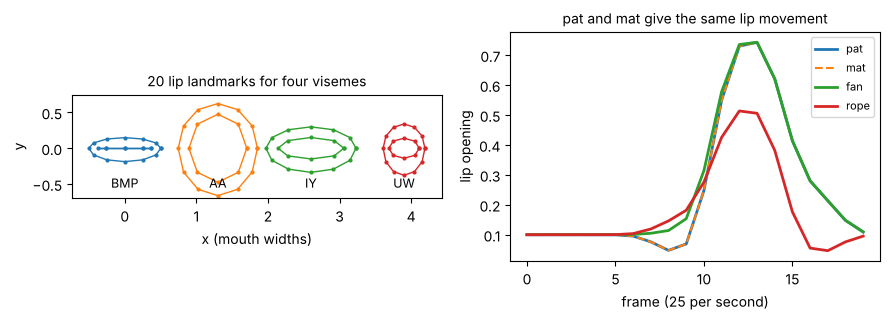

In [2]:
T, N_OUT, N_IN = 20, 12, 8          # frames per clip, outer and inner lip landmarks
N_PTS, D_AUDIO = N_OUT + N_IN, 12
rng_audio = np.random.default_rng(1)
unit = lambda v: v / np.linalg.norm(v)
manner_vec = {m: unit(rng_audio.normal(size=D_AUDIO)) for m in sorted({v[1] for v in PHONES.values()})}
place_vec = {p: unit(rng_audio.normal(size=D_AUDIO)) for p in sorted({v[2] for v in PHONES.values() if v[2]})}
audio_proto = {p: manner_vec[v[1]] + (0.35 * place_vec[v[2]] if v[2] else 0.0) for p, v in PHONES.items()}

def make_speaker(s):
    r = np.random.default_rng(1000 + s)
    return dict(width=r.uniform(0.85, 1.15), upper=r.uniform(0.10, 0.18), lower=r.uniform(0.14, 0.24),
                inner=r.uniform(0.70, 0.85), rate=r.uniform(0.8, 1.25), strength=r.uniform(0.7, 1.2), gain=r.uniform(0.7, 1.3))

def lip_points(opening, width, rounding, spk):
    # 12 outer points (index 0 = right corner, 6 = left corner) and 8 inner points around the mouth
    half_w = 0.5 * spk["width"] * width
    up, lo = spk["upper"] + 0.05 * rounding, spk["lower"] + 0.05 * rounding     # rounded lips look thicker
    phi = 2 * np.pi * np.arange(N_OUT) / N_OUT
    y_out = np.where(np.sin(phi) >= 0, (opening / 2 + up) * np.sin(phi), (opening / 2 + lo) * np.sin(phi))
    psi = 2 * np.pi * np.arange(N_IN) / N_IN
    outer = np.stack([half_w * np.cos(phi), y_out], -1)
    inner = np.stack([spk["inner"] * half_w * np.cos(psi), opening / 2 * np.sin(psi)], -1)
    return np.concatenate([outer, inner])                                         # (20, 2)

def make_clip(word, spk, rng):
    phones = WORDS[word].split()
    durs = [max(2, int(round((4 if PHONES[p][1].startswith("vowel") else 2) * spk["rate"] + rng.integers(-1, 2)))) for p in phones]
    frame_phone = ["rest"] * T
    t = rng.integers(2, T - sum(durs) - 1)                                        # random start time
    for p, d in zip(phones, durs):
        frame_phone[t:t + d] = [p] * d
        t += d
    rest = np.array(VISEMES["rest"])
    target = np.array([VISEMES[PHONES[p][0]] if p != "rest" else VISEMES["rest"] for p in frame_phone])
    target = rest + spk["strength"] * (target - rest)
    kernel = np.exp(-0.5 * np.arange(-3, 4) ** 2); kernel /= kernel.sum()          # co-articulation: smooth in time
    padded = np.concatenate([np.repeat(target[:1], 3, 0), target, np.repeat(target[-1:], 3, 0)])
    params = np.stack([np.convolve(padded[:, j], kernel, mode="valid") for j in range(3)], -1)
    params[:, 0] = np.clip(params[:, 0], 0, None)
    pts = np.stack([lip_points(*params[i], spk) for i in range(T)])                # (T, 20, 2)
    angle = rng.normal(0, 0.08) + np.cumsum(rng.normal(0, 0.01, T))                 # head roll, drifting slowly
    rot = np.stack([np.stack([np.cos(angle), -np.sin(angle)], -1), np.stack([np.sin(angle), np.cos(angle)], -1)], -2)
    shift = rng.normal(0, 0.3, 2) + np.cumsum(rng.normal(0, 0.01, (T, 2)), 0)
    pts = rng.uniform(0.7, 1.4) * np.einsum("tij,tnj->tni", rot, pts) + shift[:, None] + rng.normal(0, 0.012, pts.shape)
    audio = np.array([audio_proto[p] if p != "rest" else np.zeros(D_AUDIO) for p in frame_phone]) * spk["gain"]
    audio = np.stack([np.convolve(np.r_[audio[0, j], audio[:, j], audio[-1, j]], [0.25, 0.5, 0.25], mode="valid")
                      for j in range(D_AUDIO)], -1)
    return pts, audio, params

def normalize(pts):
    right, left = pts[:, 0], pts[:, 6]
    centre, axis = (left + right) / 2, right - left
    a = -np.arctan2(axis[:, 1], axis[:, 0])
    rot = np.stack([np.stack([np.cos(a), -np.sin(a)], -1), np.stack([np.sin(a), np.cos(a)], -1)], -2)
    q = np.einsum("tij,tnj->tni", rot, pts - centre[:, None]) / np.median(np.linalg.norm(axis, axis=1))
    velocity = np.diff(q, axis=0, prepend=q[:1])
    return np.concatenate([q, velocity], -1).astype(np.float32)                   # (T, 20, 4)

def make_set(speakers, reps, seed):
    rng = np.random.default_rng(seed)
    V, A, Y = [], [], []
    for s in speakers:
        spk = make_speaker(s)
        for _ in range(reps):
            for wi, w in enumerate(names):
                pts, audio, _ = make_clip(w, spk, rng)
                V.append(normalize(pts)); A.append(audio); Y.append(wi)
    return torch.tensor(np.array(V)), torch.tensor(np.array(A), dtype=torch.float32), np.array(Y)

V_tr, A_tr, y_tr = make_set(range(24), reps=3, seed=0)
V_te, A_te, y_te = make_set(range(24, 30), reps=5, seed=1)
print(f"training clips {len(y_tr)} (speakers 0-23), test clips {len(y_te)} (new speakers 24-29)")
print(f"video tensor {tuple(V_tr.shape)} = clips x frames x landmarks x features; audio tensor {tuple(A_tr.shape)}")

# figure: four visemes, and the lip opening over time for four words said by one speaker with the same timing
spk0 = make_speaker(0)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.3))
for k, v in enumerate(["BMP", "AA", "IY", "UW"]):
    p = lip_points(*VISEMES[v], spk0) + np.array([1.3 * k, 0])
    for idx in [np.r_[0:N_OUT, 0], np.r_[N_OUT:N_PTS, N_OUT]]:
        ax[0].plot(p[idx, 0], p[idx, 1], "o-", ms=2, lw=1, color=f"C{k}")
    ax[0].text(1.3 * k, -0.55, v, ha="center", fontsize=9)
ax[0].set_aspect("equal"); ax[0].set_ylim(-0.7, 0.75)
ax[0].set_xlabel("x (mouth widths)"); ax[0].set_ylabel("y"); ax[0].set_title("20 lip landmarks for four visemes", fontsize=10)
for w, ls in [("pat", "-"), ("mat", "--"), ("fan", "-"), ("rope", "-")]:
    _, _, params = make_clip(w, spk0, np.random.default_rng(7))      # same random timing for every word
    ax[1].plot(params[:, 0], ls, lw=2 if ls == "-" else 1.5, label=w)
ax[1].set_xlabel("frame (25 per second)"); ax[1].set_ylabel("lip opening"); ax[1].set_title("pat and mat give the same lip movement", fontsize=10)
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 3. A graph attention layer over the lip graph
The 20 landmarks form a graph: each outer point is joined to its two neighbours on the outer contour, each inner point to its neighbours on the inner contour, and each inner point to the outer points above or below it. A **graph attention** (GAT) layer (Veličković et al. 2018; message passing is Course 6 session 2) updates each point from its neighbours, with learned weights:

$$e_{ij} = \text{LeakyReLU}\big(a^\top [W h_i \,\|\, W h_j]\big), \qquad \alpha_{ij} = \frac{\exp(e_{ij})}{\sum_{k \in N(i)} \exp(e_{ik})}, \qquad h_i' = \text{ELU}\Big(\sum_{j \in N(i)} \alpha_{ij} W h_j\Big),$$

where $N(i)$ is point $i$'s neighbours plus itself. Several **heads** do this in parallel and their outputs are concatenated. We write it with a dense 20 × 20 mask, which is simple and fast for a graph this small. The check below confirms that each point's attention weights are zero outside its neighbourhood and sum to 1.

In [3]:
edges = {(k, (k + 1) % N_OUT) for k in range(N_OUT)} | {(N_OUT + k, N_OUT + (k + 1) % N_IN) for k in range(N_IN)}
for k in range(N_IN):                        # join each inner point to the outer points within 30 degrees of it
    for j in range(N_OUT):
        if abs((30 * j - 45 * k + 180) % 360 - 180) <= 30:
            edges.add((j, N_OUT + k))
adj = torch.eye(N_PTS)
for i, j in edges:
    adj[i, j] = adj[j, i] = 1.0
print(f"lip graph: {N_PTS} nodes, {len(edges)} edges, {int(adj.sum(1).mean())} neighbours per node on average (with itself)")

class GraphAttention(nn.Module):
    def __init__(self, d_in, d_head, heads, adj):
        super().__init__()
        self.W = nn.Linear(d_in, d_head * heads, bias=False)
        self.a_self = nn.Parameter(0.1 * torch.randn(heads, d_head))     # the half of a that scores the receiving node i
        self.a_nbr = nn.Parameter(0.1 * torch.randn(heads, d_head))      # the half of a that scores the neighbour j
        self.register_buffer("mask", adj > 0)
        self.heads, self.d_head = heads, d_head

    def forward(self, x):                                                # x: (M graphs, N nodes, d_in)
        M, N, _ = x.shape
        z = self.W(x).view(M, N, self.heads, self.d_head).permute(0, 2, 1, 3)        # (M, heads, N, d_head)
        e = (z * self.a_self[:, None]).sum(-1)[..., :, None] + (z * self.a_nbr[:, None]).sum(-1)[..., None, :]
        e = F.leaky_relu(e, 0.2).masked_fill(~self.mask, float("-inf"))           # (M, heads, N, N)
        alpha = torch.softmax(e, dim=-1)                                          # each row sums to 1 over the neighbours
        out = (alpha @ z).permute(0, 2, 1, 3).reshape(M, N, self.heads * self.d_head)
        return F.elu(out), alpha

gat = GraphAttention(4, 16, 2, adj)
_, alpha = gat(V_tr[0])                                                           # the 20 frames of one clip
row = alpha[0, 0, 3]                                                              # frame 0, head 0, node 3 (top of the outer lip)
print(f"node 3 attends to nodes {torch.nonzero(row).flatten().tolist()} with weights {np.round(row[row > 0].tolist(), 3)}; sum {row.sum():.3f}")
print(f"largest weight outside any neighbourhood: {alpha.masked_fill(adj.bool(), 0).max():.1e}")

lip graph: 20 nodes, 40 edges, 5 neighbours per node on average (with itself)
node 3 attends to nodes [2, 3, 4, 14] with weights [0.247 0.249 0.253 0.25 ]; sum 1.000
largest weight outside any neighbourhood: 0.0e+00


### 4. Lip reading: graph attention per frame, a GRU over time
The lip reader applies one GAT layer (2 heads of 16 features) to every frame, pools the 20 landmarks into one frame vector (mean and maximum), runs a bidirectional GRU over the 20 frames, averages its outputs over time and classifies the word. Training takes about 25 seconds on one CPU thread.

We test on the six new speakers and report three numbers: word accuracy; **group accuracy**, which counts a prediction as right if it is in the correct homophene group; and the share of errors that stay inside the true word's group, which no lip reader could avoid.

video-only model: 34,964 parameters, trained in 26 s
word accuracy on new speakers 0.618 (best possible 0.650); group accuracy 0.950
share of errors inside the true word's homophene group 0.869


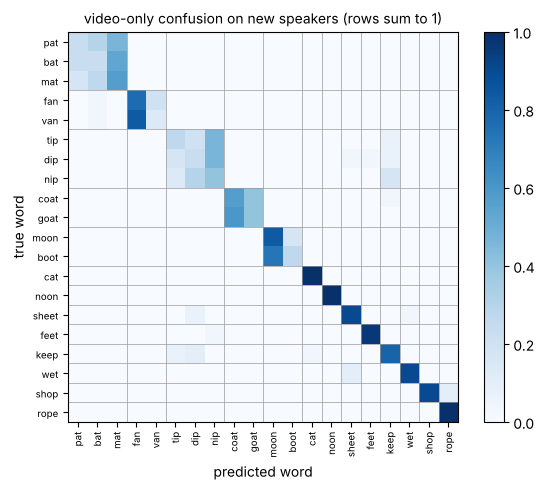

In [4]:
class Recognizer(nn.Module):
    def __init__(self, use_video=True, use_audio=False):
        super().__init__()
        self.use_video, self.use_audio = use_video, use_audio
        d = 0
        if use_video:
            self.gat = GraphAttention(4, 16, 2, adj); d += 64
        if use_audio:
            self.audio_in = nn.Linear(D_AUDIO, 32); d += 32
        self.gru = nn.GRU(d, 48, batch_first=True, bidirectional=True)
        self.out = nn.Linear(96, n_words)

    def forward(self, video, audio):
        feats = []
        if self.use_video:
            B = video.shape[0]
            h, _ = self.gat(video.reshape(B * T, N_PTS, 4))
            feats.append(torch.cat([h.mean(1), h.amax(1)], -1).view(B, T, -1))     # pool the 20 landmarks per frame
        if self.use_audio:
            audio = audio / audio.pow(2).mean(dim=(1, 2), keepdim=True).sqrt().clamp_min(1e-6)   # per-clip loudness normalization
            feats.append(F.relu(self.audio_in(audio)))
        h, _ = self.gru(torch.cat(feats, -1))
        return self.out(h.mean(1))

# speech power of each clip (mean square over its speech frames), used to set the noise for a given SNR
speech_power = lambda A: ((A ** 2).sum(-1).sum(-1) / ((A.abs().sum(-1) > 0).sum(-1) * D_AUDIO)).view(-1, 1, 1)
P_tr, P_te = speech_power(A_tr), speech_power(A_te)

def add_noise(A, P, snr_db, gen):
    # SNR in dB = 10 log10(speech power / noise power); snr_db may be one number or one per clip
    return A + torch.randn(A.shape, generator=gen) * torch.sqrt(P / 10 ** (torch.as_tensor(snr_db) / 10))

def train(model, epochs=25, lr=5e-3, snr_range=(-20, 20), seed=0):
    torch.manual_seed(seed); gen = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    steps = epochs * ((len(y_tr) + 63) // 64)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=steps)
    ys = torch.tensor(y_tr)
    for _ in range(epochs):
        perm = torch.randperm(len(ys), generator=gen)
        for i in range(0, len(ys), 64):
            idx = perm[i:i + 64]
            snr = snr_range[0] + (snr_range[1] - snr_range[0]) * torch.rand(len(idx), 1, 1, generator=gen)
            audio = add_noise(A_tr[idx], P_tr[idx], snr, gen)                    # fresh noise every time a clip is seen
            loss = F.cross_entropy(model(V_tr[idx], audio), ys[idx])
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    return model.eval()

def log_probs(model, snr_db):
    audio = add_noise(A_te, P_te, snr_db, torch.Generator().manual_seed(123))     # the same test noise for every model
    with torch.no_grad():
        return F.log_softmax(model(V_te, audio), dim=1)

t0 = time.time()
video_model = train(Recognizer(use_video=True, use_audio=False))
pred = log_probs(video_model, 0).argmax(1).numpy()
err = pred != y_te
print(f"video-only model: {sum(p.numel() for p in video_model.parameters()):,} parameters, trained in {time.time() - t0:.0f} s")
print(f"word accuracy on new speakers {np.mean(~err):.3f} (best possible {len(groups) / n_words:.3f}); "
      f"group accuracy {np.mean(group_of[pred] == group_of[y_te]):.3f}")
print(f"share of errors inside the true word's homophene group {np.mean(group_of[pred][err] == group_of[y_te][err]):.3f}")

order = [w for g in groups.values() for w in g]                                   # list the words group by group
pos = {w: i for i, w in enumerate(order)}
conf = np.zeros((n_words, n_words))
for t, p in zip(y_te, pred):
    conf[pos[names[t]], pos[names[p]]] += 1
conf /= conf.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(conf, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(n_words)); ax.set_xticklabels(order, rotation=90, fontsize=7)
ax.set_yticks(range(n_words)); ax.set_yticklabels(order, fontsize=7)
edges_g = np.cumsum([len(g) for g in groups.values()])[:-1] - 0.5
for b in edges_g:
    ax.axhline(b, color="0.6", lw=0.5); ax.axvline(b, color="0.6", lw=0.5)
ax.set_xlabel("predicted word"); ax.set_ylabel("true word")
ax.set_title("video-only confusion on new speakers (rows sum to 1)", fontsize=10)
plt.colorbar(im, ax=ax, fraction=0.046); plt.tight_layout(); plt.show()

### 5. Adding noisy audio: audio only, video only, early and late fusion
Now we add white noise to the audio at a chosen **signal-to-noise ratio** (SNR): $\text{SNR} = 10 \log_{10}(P_\text{speech}/P_\text{noise})$ dB, so 0 dB means equal power and −10 dB means ten times more noise than speech. All models are trained with a random SNR between −20 and 20 dB for each clip (multi-condition training) and tested on the new speakers at fixed SNRs. We compare:

* **audio only**: the same GRU on the audio frames;
* **video only**: the model from section 4 (it ignores the audio, so it gives the same accuracy at every SNR);
* **early fusion**: one model trained on both streams, with each frame's audio and lip vectors concatenated before the GRU;
* **late fusion**: no new training; add the log-probabilities of the audio-only and video-only models and take the best word.

audio-only and early-fusion models trained in 31 s


SNR (dB)          20     10      5      0     -5    -10    -15    -20
audio only     1.000  0.997  0.973  0.902  0.728  0.420  0.208  0.110
video only     0.618  0.618  0.618  0.618  0.618  0.618  0.618  0.618
early fusion   1.000  1.000  0.992  0.957  0.853  0.635  0.435  0.313
late fusion    1.000  1.000  1.000  0.993  0.928  0.788  0.688  0.642


early-fusion model with the audio replaced by pure noise: accuracy 0.160 (video-only model 0.618)


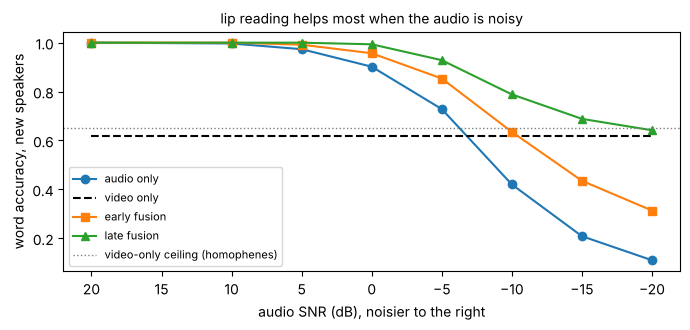

runtime so far 63 s


In [5]:
t0 = time.time()
audio_model = train(Recognizer(use_video=False, use_audio=True))
av_model = train(Recognizer(use_video=True, use_audio=True))
print(f"audio-only and early-fusion models trained in {time.time() - t0:.0f} s")

snrs = [20, 10, 5, 0, -5, -10, -15, -20]
lp_video = log_probs(video_model, 0)
acc = {k: [] for k in ["audio only", "video only", "early fusion", "late fusion"]}
for s in snrs:
    lp_audio, lp_av = log_probs(audio_model, s), log_probs(av_model, s)
    for k, lp in [("audio only", lp_audio), ("video only", lp_video), ("early fusion", lp_av), ("late fusion", lp_audio + lp_video)]:
        acc[k].append((lp.argmax(1).numpy() == y_te).mean())
print("SNR (dB)     " + "".join(f"{s:>7d}" for s in snrs))
for k, v in acc.items():
    print(f"{k:13s}" + "".join(f"{a:7.3f}" for a in v))
with torch.no_grad():   # audio replaced by pure noise (SNR -> minus infinity), so only the lips carry information
    noise_only = av_model(V_te, torch.randn(A_te.shape, generator=torch.Generator().manual_seed(5))).argmax(1).numpy()
print(f"early-fusion model with the audio replaced by pure noise: accuracy {(noise_only == y_te).mean():.3f} "
      f"(video-only model {acc['video only'][0]:.3f})")

plt.figure(figsize=(7, 3.4))
for k, st in zip(acc, ["o-", "k--", "s-", "^-"]):
    plt.plot(snrs, acc[k], st, label=k)
plt.axhline(len(groups) / n_words, color="0.5", ls=":", lw=1, label="video-only ceiling (homophenes)")
plt.gca().invert_xaxis()
plt.xlabel("audio SNR (dB), noisier to the right"); plt.ylabel("word accuracy, new speakers")
plt.title("lip reading helps most when the audio is noisy", fontsize=10); plt.legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"runtime so far {time.time() - t_start:.0f} s")

### 6. A pretrained lip reader on a real video (NOT RUN here)
Auto-AVSR (Ma et al. 2023) reports 19.1% word error rate (WER) on LRS3 from video alone, 1.0% from audio and 0.9% from both. Its authors' repository runs a pretrained model on your own clip. It needs PyTorch with torchvision and torchaudio, ffmpeg, a face tracker (RetinaFace or MediaPipe), a large model download and preferably a GPU, and its licence allows only non-commercial use. Record a short English clip of someone who has agreed to be filmed.

In [ ]:
# NOT RUN: needs the Auto-AVSR code, torchvision, torchaudio, ffmpeg, MediaPipe and an 891 MB model download (GPU recommended)
# In a Colab or Kaggle terminal first:
#   git clone https://github.com/mpc001/Visual_Speech_Recognition_for_Multiple_Languages
#   cd Visual_Speech_Recognition_for_Multiple_Languages && pip install -r requirements.txt mediapipe
#   then download the LRS3 visual-only model (WER 19.1) from the README's model zoo into ./benchmarks/LRS3/models
import subprocess
repo = "Visual_Speech_Recognition_for_Multiple_Languages"
subprocess.run(["python", "infer.py", "config_filename=./configs/LRS3_V_WER19.1.ini",
                "data_filename=/content/my_clip.mp4", "detector=mediapipe"], cwd=repo, check=True)
# Then compare the printed transcript with what was said, and count the words it got wrong.

### 7. Exercises

In [6]:
# TODO: a lip reader without the graph. Replace the GraphAttention layer with a small MLP on each frame's
# 80 numbers (20 landmarks x 4 features), for example nn.Sequential(nn.Linear(80, 64), nn.ELU()), keep the same GRU,
# train it with train(...) and report its parameter count, word accuracy and group accuracy on the new speakers.
# Is the graph worth it here? Try it again after removing 5 random landmarks from every test frame (set them to 0).
def no_graph_baseline():
    return None          # replace with your code; return (parameters, word accuracy, group accuracy)

r = no_graph_baseline()
print("not done yet" if r is None else r)

not done yet


In [7]:
# TODO: a warm start for early fusion. Build Recognizer(use_video=True, use_audio=True), copy the trained lip branch
# into it before training (av.gat.load_state_dict(video_model.gat.state_dict())), train it, and print its accuracy at
# every SNR in snrs next to the early- and late-fusion rows above. Does a pretrained lip branch fix early fusion at
# -15 and -20 dB? Then train an early-fusion model with snr_range=(-10, 20) and test it at -15 and -20 dB.
def warm_start_fusion():
    return None          # replace with your code; return a list of accuracies, one per SNR

r = warm_start_fusion()
print("not done yet" if r is None else r)

not done yet


### What to notice
(Written from the run above; your numbers will match if you keep the seeds.)

1. **Homophenes set a hard ceiling for lip reading.** The 20 words have only 13 distinct viseme sequences, so no lip reader can beat 13/20 = 0.650 when all words are equally common. The graph attention model reached 0.618 on six speakers it had never seen. Its group accuracy was 0.950, and 0.869 of its errors stayed inside the true word's homophene group: the confusion matrix shows one block per group, where the model mostly gives one answer (for example *mat* for *pat*, *bat* and *mat*), which is as good as any guess. Only 30 of the 229 errors left the group, and 14 of those were between *keep* and *tip*, *dip* or *nip*, whose first sounds (k against t, d, n) look alike: near-homophenes.
2. **The attention layer respects the graph.** Before training, node 3 spread its attention almost evenly over its neighbours 2, 3, 4 and 14 (weights 0.247 to 0.253, summing to 1.000), and every weight outside a neighbourhood was exactly 0. The model is small: 34,964 parameters.
3. **Audio wins when it is clean and collapses in noise.** The audio-only model scored 1.000 at 20 dB and 0.902 at 0 dB, then 0.420 at −10 dB and 0.110 at −20 dB. The video-only model is unaffected by audio noise (0.618 everywhere), so it beat audio from −10 dB down; the lines cross between −5 and −10 dB.
4. **Late fusion was the best model, or tied for best, at every SNR.** Adding the two models' log-probabilities gave 0.993 at 0 dB, 0.928 at −5 dB, 0.788 at −10 dB and 0.642 at −20 dB; from 5 dB down it was above both single streams. The audio settles the homophenes (voicing and nasality), and the lips settle the place of articulation that noise hides.
5. **Against expectation, early fusion did worse than late fusion.** Trained on both streams at once, it was below late fusion at every SNR from 5 dB down (0.957 against 0.993 at 0 dB) and below video only at −15 and −20 dB (0.435 and 0.313). With the audio replaced by pure noise it scored 0.160, against 0.618 for the video-only model: during joint training it leaned on the easier stream, the audio, and its lip branch learned little. The second exercise tests whether a pretrained lip branch fixes this. This is one seed on synthetic data, and with 600 test clips each accuracy has a standard error of about 0.02, so treat gaps of a few points as uncertain.